# Search → series → pandas chart

Find an indicator, load a country series and plot it. Works on the free trial, no key needed.

In [1]:
%pip install -q econdash pandas matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from econdash import EconDash

ed = EconDash()  # free trial; set ECONDASH_API_KEY for full access
for ind in ed.search_indicators("inflation", limit=5):
    print(f"{ind.slug:40} {ind.name_en} ({ind.source})")

inflation-expectations-breakeven         Inflation expectations (breakeven) (FRED)
cpi-inflation-rate-percent               CPI inflation rate % (World Bank)
cpi-inflation                            CPI Inflation (IMF)
food-inflation                           Food inflation (BLS)
energy-inflation                         Energy inflation (BLS)


In [3]:
ind = ed.get_indicator("cpi-inflation-rate-percent")
print(ind.name_en, "|", ind.unit, "|", ind.frequency)
print("Source:", ind.source_url)
print("Licence:", ind.license_name, ind.license_url)

CPI inflation rate % | % | annual
Source: https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG
Licence: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/


In [4]:
import pandas as pd

s = ed.get_series(ind.slug, "USA", start=1990)
df = pd.DataFrame([p.model_dump() for p in s.data]).set_index("date")
df.tail()

,value,country,country_name,is_projection
date,,,,
2020-01-01,1.233584,USA,United States,None
2021-01-01,4.697859,USA,United States,None
2022-01-01,8.002800,USA,United States,None
2023-01-01,4.116338,USA,United States,None
2024-01-01,2.949525,USA,United States,None


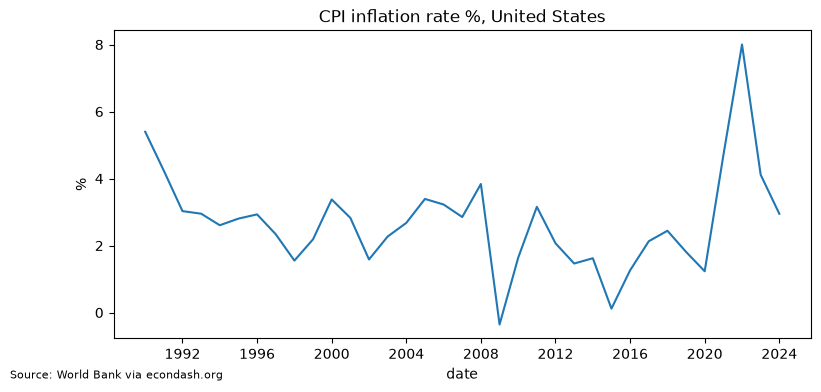

In [5]:
ax = df["value"].plot(title=f"{s.indicator_name_en}, United States", figsize=(9, 4))
ax.set_ylabel(s.unit or "")
ax.figure.text(0.01, 0.01, f"Source: {ind.source} via econdash.org", fontsize=8);